# Chicago Taxi Trips — Week of 11–17 September 2023

A descriptive summary of reported taxi trips (`trips.csv`, Monday 2023-09-11 to Sunday 2023-09-17). After cleaning, 135,131 of 135,768 reported trips are used (637 excluded, 0.47%). Figures describe *reported* trips, not total market volume.

## Summary

- **When is demand highest?** Monday–Thursday are steady at about 22k trips a day (Wednesday busiest, 22,599); Friday is lower (20.1k) and the weekend is much quieter (Saturday 12,635 is the quietest day, Sunday 13,300). The busiest start hour is 17:00 (weekday peak; the weekend peak is around 15:00) and the quietest is 03:00; weekends have a larger share of overnight trips and a much smaller morning rush.
- **Where do trips start?** Pickups are concentrated: the top 10 community areas start 85.1% of trips, and areas 76, 8 and 32 alone 60.5%. Area 76 is first on both measures, with 23.3% of trips but 43.0% of revenue (average trip total $54.83 vs $16–$19 in areas 8, 32 and 28). Only 2.76% of trips have no pickup community area.
- **How do riders pay and tip?** Credit Card accounts for 44.5% of trips and 59.6% of revenue (average fare $28.78), Cash 29.3% of trips, Mobile 13.8%. Tips are only recorded on card and mobile trips (93–94% of them have one); there they average about 22% of fare. Tip percentages for Cash, Prcard and Unknown are near zero because tips are not recorded, so they are not comparable.
- **Which companies carry the trips?** Flash Cab (19.2%) and Taxi Affiliation Services (19.0%) carry 38% of trips between them; the top 10 companies carry 92.2%. Taxi Affiliation Services has the most revenue ($724,913) and the largest fleet (457 taxis); 2,656 distinct taxis appear in total.
- **Data quality:** 637 rows were excluded for unusable money fields (missing totals, fares under the $3.25 minimum, tolls/extras above $100, implausible manually keyed fares); all assumptions are listed in Section 1.

# ## 1. Data loading and cleaning

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

FIG_DIR = "figures/analysis"
os.makedirs(FIG_DIR, exist_ok=True)

# Chart style: single blue, light grid, no top/right spines
BLUE = "#2a78d6"; ORANGE = "#eb6834"; GREY = "#9a9994"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
})

raw = pd.read_csv("trips.csv", dtype={"pickup_census_tract": "string", "dropoff_census_tract": "string"})
df = raw.copy()
print("Shape:", df.shape)
print("Duplicate trip_id:", df["trip_id"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Shape: (135768, 23)
Duplicate trip_id: 0
Fully duplicated rows: 0


In [2]:
print(df.dtypes)
print()
miss = df.isna().sum().to_frame("missing"); miss["pct"] = miss["missing"] / len(df) * 100
print(miss[miss.missing > 0])

trip_id                           str
taxi_id                           str
trip_start_timestamp              str
trip_end_timestamp                str
trip_seconds                  float64
trip_miles                    float64
pickup_census_tract            string
dropoff_census_tract           string
pickup_community_area         float64
dropoff_community_area        float64
fare                          float64
tips                          float64
tolls                         float64
extras                        float64
trip_total                    float64
payment_type                      str
company                           str
pickup_centroid_latitude      float64
pickup_centroid_longitude     float64
pickup_centroid_location          str
dropoff_centroid_latitude     float64
dropoff_centroid_longitude    float64
dropoff_centroid_location         str
dtype: object

                            missing   pct
trip_end_timestamp                1  0.00
trip_seconds               

In [3]:
num = ["trip_seconds","trip_miles","fare","tips","tolls","extras","trip_total"]
print(df[num].describe(percentiles=[.01,.05,.5,.95,.99]).T)

                  count     mean      std  min   1%    5%      50%      95%      99%       max
trip_seconds 135,735.00 1,346.54 1,762.25 0.00 0.00 22.00 1,020.00 3,382.30 4,872.98 86,160.00
trip_miles   135,768.00     6.94     7.85 0.00 0.00  0.00     3.24    18.76    27.14    792.90
fare         135,444.00    23.87    19.60 0.00 3.25  4.25    17.75    53.50    75.50    911.00
tips         135,444.00     3.38     4.67 0.00 0.00  0.00     2.00    11.88    17.10    130.00
tolls        135,444.00     0.13    20.42 0.00 0.00  0.00     0.00     0.00     0.00  4,444.44
extras       135,444.00     2.54    18.31 0.00 0.00  0.00     0.00     7.00    35.50  4,445.44
trip_total   135,444.00    30.12    43.93 0.00 3.25  5.25    21.25    70.50   104.43  8,901.13


In [4]:
# Parse timestamps and normalise company names
df["start"] = pd.to_datetime(df["trip_start_timestamp"])
df["end"] = pd.to_datetime(df["trip_end_timestamp"])
print("Start range:", df["start"].min(), "->", df["start"].max())
print("Start minutes present:", sorted(df["start"].dt.minute.unique()))

# Variant spellings of the same company (identified by inspecting all 32 raw names)
company_map = {
    "Taxicab Insurance Agency, LLC": "Taxicab Insurance Agency Llc",
    "Choice Taxi Association Inc": "Choice Taxi Association",
}
df["company_raw"] = df["company"]
df["company"] = df["company"].replace(company_map)
print("Distinct company names: raw =", df["company_raw"].nunique(), "-> normalised =", df["company"].nunique())
print("Rows renamed:", (df["company"] != df["company_raw"]).sum())

Start range: 2023-09-11 00:00:00 -> 2023-09-17 23:45:00
Start minutes present: [np.int32(0), np.int32(15), np.int32(30), np.int32(45)]
Distinct company names: raw = 32 -> normalised = 30
Rows renamed: 3443


In [5]:
# Checks that are FLAGGED but not used to exclude rows (no business question uses miles or duration)
df["parts_sum"] = df[["fare","tips","tolls","extras"]].sum(axis=1, min_count=4)
df["total_gap"] = (df["trip_total"] - df["parts_sum"]).round(2)
mph = df["trip_miles"] / (df["trip_seconds"] / 3600)

checks = {
    "trip_seconds missing": df["trip_seconds"].isna(),
    "trip_seconds == 0": df["trip_seconds"] == 0,
    "trip_miles == 0": df["trip_miles"] == 0,
    "trip_miles > 100": df["trip_miles"] > 100,
    "trip_seconds > 12 h": df["trip_seconds"] > 12 * 3600,
    "implied speed > 100 mph": mph > 100,
    "trip_total - parts == 0.50 (card-fee-sized gap)": df["total_gap"] == 0.5,
    "trip_total - parts > 0.50 (unexplained gap)": df["total_gap"] > 0.5,
    "tips > fare": df["tips"] > df["fare"],
}
print(pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="rows").to_frame().assign(pct=lambda t: t.rows / len(df) * 100))
print()
print("Any trip_total BELOW sum of parts?", int((df["total_gap"] < -0.01).sum()))
print("0.50 gap by payment type:\n", df.loc[df.total_gap == 0.5, "payment_type"].value_counts().to_string())
print("Unexplained gap sizes:\n", df.loc[df.total_gap > 0.5, "total_gap"].value_counts().to_string())

                                                  rows   pct
trip_seconds missing                                33  0.02
trip_seconds == 0                                 2731  2.01
trip_miles == 0                                  13993 10.31
trip_miles > 100                                    11  0.01
trip_seconds > 12 h                                 61  0.04
implied speed > 100 mph                            202  0.15
trip_total - parts == 0.50 (card-fee-sized gap)  46522 34.27
trip_total - parts > 0.50 (unexplained gap)       1675  1.23
tips > fare                                        864  0.64

Any trip_total BELOW sum of parts? 0
0.50 gap by payment type:
 payment_type
Credit Card    42409
Mobile          4110
Cash               3
Unexplained gap sizes:
 total_gap
3.00    804
2.50    751
1.00    109
1.95      5
1.50      4
2.00      2


In [6]:
# Are zero-mile trips real rides? Compare fare/duration of zero-mile trips with a duration to the rest
zm = (df["trip_miles"] == 0) & (df["trip_seconds"] > 60)
print("Zero-mile trips lasting > 1 min:", zm.sum())
print(df.loc[zm, ["fare","trip_seconds"]].describe().T[["count","50%","mean"]])
print("\nAll other trips with duration > 1 min:")
print(df.loc[~zm & (df["trip_seconds"] > 60), ["fare","trip_seconds"]].describe().T[["count","50%","mean"]])

Zero-mile trips lasting > 1 min: 7021
                count    50%     mean
fare         7,011.00   9.50    17.90
trip_seconds 7,021.00 626.00 1,093.30

All other trips with duration > 1 min:
                  count      50%     mean
fare         119,773.00    19.75    24.49
trip_seconds 120,065.00 1,142.00 1,457.36


In [7]:
# Exclusion rules (money fields that cannot be trusted). Every question below uses the same cleaned set.
rules = {
    "E1 money fields missing (fare/tips/tolls/extras/trip_total)": df["trip_total"].isna(),
    "E2 fare below the $3.25 meter minimum (incl. zero fares)": df["fare"] < 3.25,
    "E3 tolls or extras above $100": (df["tolls"] > 100) | (df["extras"] > 100),
    "E4 implausible fare: >$100 on a <5 mi, <30 min (or unknown-length) trip, or any fare >$500":
        ((df["fare"] > 100) & (df["trip_miles"] < 5) & ~(df["trip_seconds"] >= 1800)) | (df["fare"] > 500),
}
flag_df = pd.DataFrame(rules)
excluded = flag_df.any(axis=1)

summary = pd.DataFrame({
    "rows_flagged": flag_df.sum(),
    "newly_excluded": [int((flag_df.iloc[:, :i+1].any(axis=1) & ~flag_df.iloc[:, :i].any(axis=1)).sum()) for i in range(len(rules))],
})
print(summary)
print()
print("Total rows excluded:", int(excluded.sum()), f"({excluded.mean()*100:.2f}% of {len(df):,})")
print("Rows with >1 rule:", int((flag_df.sum(axis=1) > 1).sum()))
print("Excluded by payment type:\n", df.loc[excluded, "payment_type"].value_counts().to_string())

                                                    rows_flagged  newly_excluded
E1 money fields missing (fare/tips/tolls/extras...           324             324
E2 fare below the $3.25 meter minimum (incl. ze...           171             171
E3 tolls or extras above $100                                 16              16
E4 implausible fare: >$100 on a <5 mi, <30 min ...           126             126

Total rows excluded: 637 (0.47% of 135,768)
Rows with >1 rule: 0
Excluded by payment type:
 payment_type
Cash           506
Credit Card    127
No Charge        3
Unknown          1


In [8]:
clean = df.loc[~excluded].copy()
print("Cleaned shape:", clean.shape)
print("Any remaining NaN in money fields:", int(clean[["fare","tips","tolls","extras","trip_total"]].isna().sum().sum()))
print("Max fare / tolls / extras / trip_total:", clean[["fare","tolls","extras","trip_total"]].max().to_dict())
print("Revenue (sum trip_total): all rows with money = ${:,.0f}; cleaned = ${:,.0f}; removed = ${:,.0f} ({:.2%})".format(
    df["trip_total"].sum(), clean["trip_total"].sum(), df["trip_total"].sum() - clean["trip_total"].sum(),
    (df["trip_total"].sum() - clean["trip_total"].sum()) / df["trip_total"].sum()))
print("Rows left with total gap > 0.50 (kept, revenue uses trip_total as reported):", int((clean.total_gap > 0.5).sum()),
      "| their summed gap = ${:,.0f}".format(clean.loc[clean.total_gap > 0.5, "total_gap"].sum()))
print("Rows left with miles==0 or seconds==0 (kept):", int(((clean.trip_miles == 0) | (clean.trip_seconds == 0)).sum()))

Cleaned shape: (135131, 28)
Any remaining NaN in money fields: 0
Max fare / tolls / extras / trip_total: {'fare': 471.5, 'tolls': 75.0, 'extras': 100.0, 'trip_total': 483.0}
Revenue (sum trip_total): all rows with money = $4,079,349; cleaned = $4,026,305; removed = $53,044 (1.30%)
Rows left with total gap > 0.50 (kept, revenue uses trip_total as reported): 1635 | their summed gap = $4,376
Rows left with miles==0 or seconds==0 (kept): 13824


# ### Cleaning decisions and assumptions
#
# **Unit and wording.** One row is one *reported* trip. All figures below describe reported trips, not total market volume (the City notes that not every trip is reported).
#
# **One cleaned set for every question.** Rule-based exclusions are applied once and every table and chart uses the same 135,131 trips. No question uses miles or duration, so exclusions target only rows whose *money* fields cannot be trusted:
#
# | Rule | Rows excluded | Rationale |
# |---|---:|---|
# | E1 – fare/tips/tolls/extras/trip_total all missing | 324 | No revenue can be computed (323 of 324 are cash trips, so cash is very slightly under-counted). Not imputed or set to zero. |
# | E2 – fare below the $3.25 meter minimum (incl. 135 zero fares) | 171 | Fare is below the minimum fare any metered trip pays (the 1st percentile of fares is exactly $3.25). 131 of the zero fares are cash. |
# | E3 – tolls or extras above $100 | 16 | Includes tolls of $4,444.44 and $4,111.10 (keying errors). Next-largest toll is $75. |
# | E4 – fare > $100 on a trip under 5 miles and under 30 minutes (or unknown length), or any fare > $500 | 126 | Mostly round-number card fares ($150, $225 …) on trips with ~0 miles and seconds of duration, up to $911. They cannot be produced by a meter, so they look manually keyed. Real long trips (e.g. 195 miles, $471) are retained. |
# | **Total** | **637 (0.47% of trips, 1.3% of revenue)** | No row triggers more than one rule. |
#
# **Flagged but kept** (no business question depends on them):
# - Zero miles (13,993 rows, 10%) – the fare and duration look like short real rides with a missing distance (median fare $9.50, ~10 min), so they stay in. Zero seconds (2,731 rows), implied speed above 100 mph (202 rows incl. 94 with miles but zero seconds), distances above 100 miles (11) and durations above 12 h (61) are also kept. `trip_seconds` is missing on 33 rows.
# - **`trip_total` vs. sum of parts.** `trip_total` is never below the sum of fare + tips + tolls + extras. A gap of exactly $0.50 appears on 46,522 rows, almost all Credit Card/Mobile, which looks like an un-itemised card fee, so I treat it as expected. 1,675 rows have a larger unexplained gap ($1–$3, mostly $2.50/$3.00; 1,635 remain after cleaning, $4,376 in total ≈ 0.1% of revenue). These are kept, and **revenue is defined as `trip_total` as reported**.
# - `tips > fare` on 864 rows (0.6%) is kept; tipping is summarised with robust measures in Question 3.
#
# **Other assumptions**
# - *Company names:* two spelling variants are merged (`Taxicab Insurance Agency, LLC` → `Taxicab Insurance Agency Llc`; `Choice Taxi Association Inc` → `Choice Taxi Association`; 3,443 rows). `Taxi Affiliation Services Llc - Yell…` (75 trips, truncated name) is left separate; merging it would not change the top 10 or its order.
# - *Time:* timestamps are rounded to 15 minutes, so the "hour" of a trip is the hour of the rounded start time (a trip can be up to ~7 minutes from its bucket). Day is the calendar day of the rounded start, so a Friday-night trip after midnight counts as Saturday. "Weekend" means Saturday + Sunday. No time-zone adjustment is applied (timestamps are treated as Chicago local time).
# - *Geography:* community-area numbers are used as given (no names, per the brief). Census tracts are not used.
# - *Payment types* are used as reported. `Prcard` is kept as its own category (its exact meaning is not documented).

# ## 2. Question 1 — When is demand highest?

In [9]:
DAYS = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
clean["dow"] = pd.Categorical(clean["start"].dt.day_name(), categories=DAYS, ordered=True)
clean["hour"] = clean["start"].dt.hour
clean["is_weekend"] = clean["dow"].isin(["Saturday","Sunday"])

by_day = clean.groupby("dow", observed=True).agg(trips=("trip_id","size"), revenue=("trip_total","sum"))
by_day["share_of_week_%"] = by_day["trips"] / by_day["trips"].sum() * 100
print(by_day)
print()
by_hour = clean.groupby("hour").size().rename("trips").to_frame()
by_hour["share_%"] = by_hour["trips"] / by_hour["trips"].sum() * 100
print(by_hour.T.round(1).to_string())
print()
print("Busiest hour:", by_hour["trips"].idxmax(), "-> trips", by_hour["trips"].max(), "| quietest hour:", by_hour["trips"].idxmin(), "-> trips", by_hour["trips"].min())

           trips    revenue  share_of_week_%
dow                                         
Monday     22079 659,739.12            16.34
Tuesday    21944 609,988.04            16.24
Wednesday  22599 643,458.20            16.72
Thursday   22438 675,341.23            16.60
Friday     20136 603,677.99            14.90
Saturday   12635 364,331.89             9.35
Sunday     13300 469,768.45             9.84

hour          0        1      2      3      4        5        6        7        8        9        10       11       12       13       14       15       16       17       18       19       20       21       22       23
trips   2,389.00 1,412.00 767.00 627.00 859.00 1,352.00 2,582.00 4,584.00 6,581.00 7,584.00 7,648.00 8,038.00 8,696.00 8,772.00 9,241.00 9,418.00 9,163.00 9,463.00 8,891.00 7,996.00 6,769.00 5,416.00 3,981.00 2,902.00
share_%     1.80     1.00   0.60   0.50   0.60     1.00     1.90     3.40     4.90     5.60     5.70     5.90     6.40     6.50     6.80     7.00     6.80    

In [10]:
# Average trips per day for weekdays (Mon-Fri, 5 days) vs weekend (Sat-Sun, 2 days), by hour
day_counts = clean.groupby("is_weekend")["start"].apply(lambda s: s.dt.date.nunique())
print("Days per group:", day_counts.rename({False:"weekday", True:"weekend"}).to_dict())
hourly = clean.groupby(["is_weekend","hour"]).size().unstack(0)
hourly.columns = ["weekday","weekend"]
hourly["weekday"] /= 5; hourly["weekend"] /= 2
print(hourly.round(0).astype(int).T.to_string())
print()
print("Avg trips/day: weekday = {:,.0f}, weekend = {:,.0f}  (weekend is {:.0%} of weekday)".format(
    hourly.weekday.sum(), hourly.weekend.sum(), hourly.weekend.sum()/hourly.weekday.sum()))
print("Peak hour weekday:", hourly.weekday.idxmax(), "| weekend:", hourly.weekend.idxmax())
print("Quietest hour weekday:", hourly.weekday.idxmin(), "| weekend:", hourly.weekend.idxmin())
print("Share of day's trips 0-4h: weekday {:.1%}, weekend {:.1%}".format(hourly.weekday[:5].sum()/hourly.weekday.sum(), hourly.weekend[:5].sum()/hourly.weekend.sum()))
print("Share of day's trips 7-9h (AM rush): weekday {:.1%}, weekend {:.1%}".format(hourly.weekday[7:10].sum()/hourly.weekday.sum(), hourly.weekend[7:10].sum()/hourly.weekend.sum()))
print("Share of day's trips 15-18h: weekday {:.1%}, weekend {:.1%}".format(hourly.weekday[15:19].sum()/hourly.weekday.sum(), hourly.weekend[15:19].sum()/hourly.weekend.sum()))
print("Share of day's trips 20-23h: weekday {:.1%}, weekend {:.1%}".format(hourly.weekday[20:].sum()/hourly.weekday.sum(), hourly.weekend[20:].sum()/hourly.weekend.sum()))
# Friday vs Mon-Thu by hour
fri = clean[clean.dow=="Friday"].groupby("hour").size(); mt = clean[clean.dow.isin(DAYS[:4])].groupby("hour").size()/4
print("\nFriday minus Mon-Thu average, trips by hour:\n", (fri - mt).round(0).astype(int).to_string())

Days per group: {'weekday': 5, 'weekend': 2}


hour      0    1    2    3    4    5    6    7     8     9     10    11    12    13    14    15    16    17    18    19    20   21   22   23
weekday  333  167   75   75  119  219  436  813  1156  1303  1272  1304  1395  1432  1492  1514  1491  1549  1459  1282  1071  844  604  433
weekend  362  288  195  126  132  128  201  260   400   536   645   759   860   806   892   923   853   859   798   793   707  598  480  369

Avg trips/day: weekday = 21,839, weekend = 12,968  (weekend is 59% of weekday)
Peak hour weekday: 17 | weekend: 15
Quietest hour weekday: 3 | weekend: 3
Share of day's trips 0-4h: weekday 3.5%, weekend 8.5%
Share of day's trips 7-9h (AM rush): weekday 15.0%, weekend 9.2%
Share of day's trips 15-18h: weekday 27.5%, weekend 26.5%
Share of day's trips 20-23h: weekday 13.5%, weekend 16.6%



Friday minus Mon-Thu average, trips by hour:
 hour
0      95
1      60
2      63
3      45
4      22
5      34
6       6
7     -96
8    -308
9    -304
10   -197
11   -164
12   -176
13   -183
14   -220
15   -157
16   -134
17   -160
18   -114
19    -58
20    -91
21    -65
22    -36
23      5


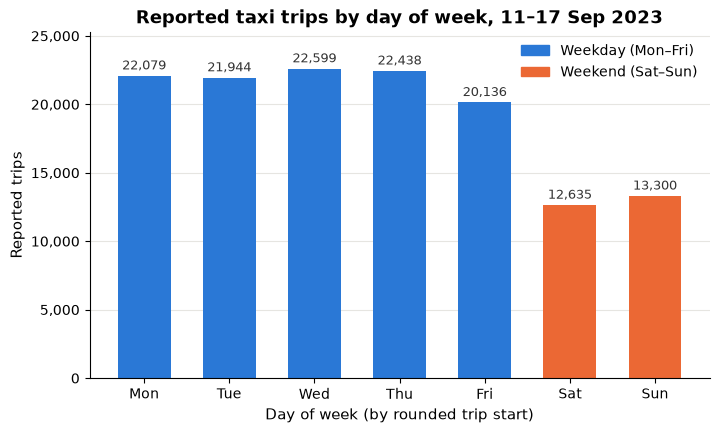

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cols = [GREY if d in ("Saturday","Sunday") else BLUE for d in by_day.index]
cols = [ORANGE if d in ("Saturday","Sunday") else BLUE for d in by_day.index]
bars = ax.bar([d[:3] for d in by_day.index], by_day["trips"], color=cols, width=0.62)
for b, v in zip(bars, by_day["trips"]):
    ax.text(b.get_x() + b.get_width()/2, v + 250, f"{v:,}", ha="center", va="bottom", fontsize=9, color="#333")
ax.set_title("Reported taxi trips by day of week, 11–17 Sep 2023")
ax.set_xlabel("Day of week (by rounded trip start)")
ax.set_ylabel("Reported trips")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(0, by_day["trips"].max() * 1.12)
ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Weekday (Mon–Fri)"), Patch(color=ORANGE, label="Weekend (Sat–Sun)")], frameon=False, loc="upper right")
plt.savefig(f"{FIG_DIR}/01_trips_by_day.png", dpi=150, bbox_inches="tight")
plt.show()

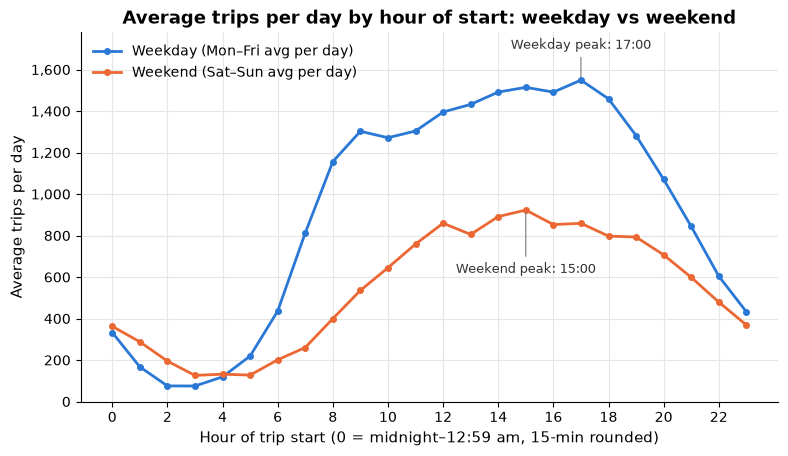

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(hourly.index, hourly["weekday"], color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon–Fri avg per day)")
ax.plot(hourly.index, hourly["weekend"], color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat–Sun avg per day)")
arrow = dict(arrowstyle="-", color="#777", lw=0.8)
ax.annotate("Weekday peak: 17:00", (17, hourly.weekday[17]), xytext=(17, 1700), ha="center", fontsize=9, color="#333", arrowprops=arrow)
ax.annotate("Weekend peak: 15:00", (15, hourly.weekend[15]), xytext=(15, 620), ha="center", fontsize=9, color="#333", arrowprops=arrow)
ax.set_title("Average trips per day by hour of start: weekday vs weekend")
ax.set_xlabel("Hour of trip start (0 = midnight–12:59 am, 15-min rounded)")
ax.set_ylabel("Average trips per day")
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(0, hourly.max().max() * 1.15)
ax.legend(frameon=False, loc="upper left")
plt.savefig(f"{FIG_DIR}/02_trips_by_hour_weekday_weekend.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q1).** Weekday demand is steady Monday–Thursday (21.9k–22.6k reported trips a day, busiest day Wednesday with 22,599). Friday is somewhat lower (20.1k) and the weekend is much quieter: Saturday is the quietest day (12,635), Sunday 13,300, so an average weekend day carries about 59% of the trips of an average weekday. By hour, the busiest start hour over the week is 17:00 (9,463 trips, 7.0% of the week), with 15:00 almost level (9,418); the quietest is 03:00 (627 trips). Weekdays have a sharp morning ramp from 06:00–09:00 and stay high until about 19:00 (peak 17:00); weekends build slowly to a lower peak around 15:00 and have a much larger share of overnight trips (8.5% of the day's trips between midnight and 4:59 am vs 3.5% on weekdays).
#
# *Possible follow-up:* Friday's daytime volume is 8–12% below the Monday–Thursday average in most hours; with only one week of data we cannot tell whether that is typical or specific to this week.

# ## 3. Question 2 — Where do trips start?
#
# Community areas are shown by their number, since names are outside data. Trips with no pickup community area are mostly trips starting outside Chicago, per `dataset.md`.

In [13]:
n_all = len(clean); rev_all = clean["trip_total"].sum()
no_area = clean["pickup_community_area"].isna()
print(f"Trips with no pickup community area: {no_area.sum():,} of {n_all:,} = {no_area.mean():.2%}  | revenue share = {clean.loc[no_area,'trip_total'].sum()/rev_all:.2%}")
print("  ...of which have a pickup centroid anyway:", int((no_area & clean.pickup_centroid_latitude.notna()).sum()), "(left as 'no area')")
print("Distinct pickup community areas:", clean["pickup_community_area"].nunique())

area = (clean.dropna(subset=["pickup_community_area"])
        .assign(area=lambda t: t["pickup_community_area"].astype(int))
        .groupby("area").agg(trips=("trip_id","size"), total_revenue=("trip_total","sum")))
area["avg_trip_total"] = area["total_revenue"] / area["trips"]
area["pct_of_all_trips"] = area["trips"] / n_all * 100
area["pct_of_all_revenue"] = area["total_revenue"] / rev_all * 100

top_trips = area.sort_values("trips", ascending=False).head(10)
top_rev = area.sort_values("total_revenue", ascending=False).head(10)
print("\nTop 10 pickup community areas by trip count:")
print(top_trips.round(2))
print("\nTop 10 pickup community areas by total trip_total:")
print(top_rev.round(2))
print("\nSame 10 areas in both lists?", set(top_trips.index) == set(top_rev.index))
print("Top-10 (by trips) share of all trips: {:.1%} | top-3: {:.1%}".format(top_trips.trips.sum()/n_all, top_trips.trips.head(3).sum()/n_all))

Trips with no pickup community area: 3,734 of 135,131 = 2.76%  | revenue share = 3.20%
  ...of which have a pickup centroid anyway: 38 (left as 'no area')
Distinct pickup community areas: 77

Top 10 pickup community areas by trip count:
      trips  total_revenue  avg_trip_total  pct_of_all_trips  pct_of_all_revenue
area                                                                            
76    31542   1,729,384.53           54.83             23.34               42.95
8     28204     516,452.82           18.31             20.87               12.83
32    22059     420,126.66           19.05             16.32               10.43
28    11242     184,475.55           16.41              8.32                4.58
33     6671     171,962.86           25.78              4.94                4.27
56     5398     251,811.35           46.65              3.99                6.25
6      3925      77,931.57           19.86              2.90                1.94
7      2536      48,601.58        

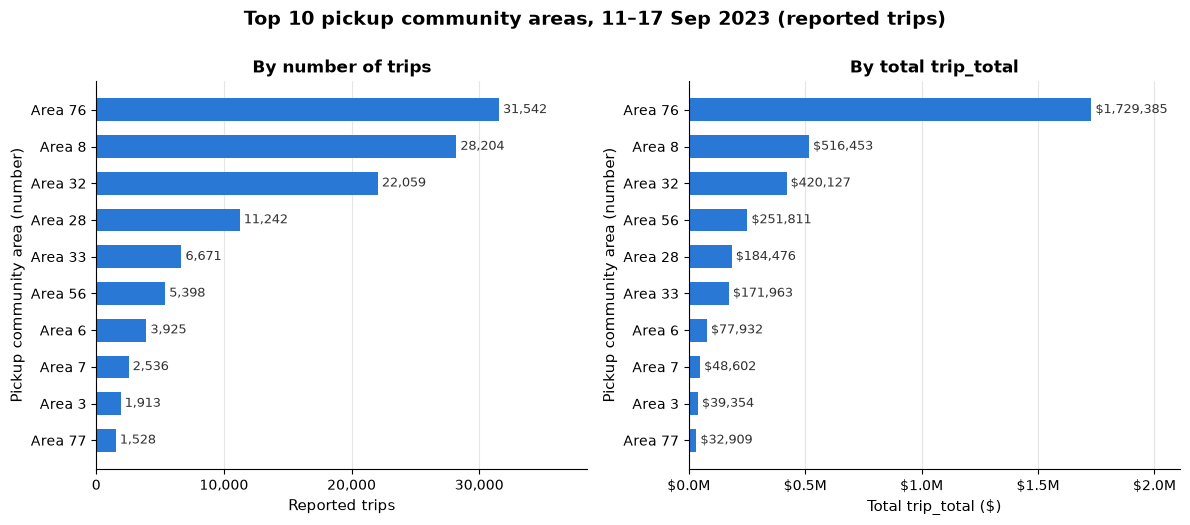

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, data, col, title, xl, fmt in [
    (axes[0], top_trips["trips"], "trips", "By number of trips", "Reported trips", lambda v: f"{v:,.0f}"),
    (axes[1], top_rev["total_revenue"], "rev", "By total trip_total", "Total trip_total ($)", lambda v: f"${v/1e6:,.1f}M"),
]:
    d = data.iloc[::-1]
    ax.barh([f"Area {i}" for i in d.index], d.values, color=BLUE, height=0.62)
    for y, v in enumerate(d.values):
        ax.text(v + d.max() * 0.01, y, f"{v:,.0f}" if col == "trips" else f"${v:,.0f}", va="center", fontsize=9, color="#333")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xl)
    ax.set_ylabel("Pickup community area (number)")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _, f=fmt: f(v)))
    ax.set_xlim(0, d.max() * 1.22)
    ax.xaxis.set_major_locator(mtick.MultipleLocator(10000 if col == "trips" else 500000))
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 10 pickup community areas, 11–17 Sep 2023 (reported trips)", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_top10_pickup_areas.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q2).** Pickups are very concentrated: 77 community areas appear, but the top 10 account for 85.1% of reported trips and the top three (areas 76, 8 and 32) for 60.5%. The same 10 areas lead by trip count and by revenue, but in a different order. Area 76 is first on both, with 23.3% of trips but 43.0% of revenue, because its average `trip_total` ($54.83) is about three times that of areas 8, 32 and 28 ($16–$19); area 56 also has a high average ($46.65), moving it from 6th by trips to 4th by revenue. Only 2.76% of trips (3,734) have no pickup community area (2.81% before cleaning), consistent with trips starting outside Chicago, and these carry 3.2% of revenue.
#
# *Possible follow-up:* map community-area numbers to names and check whether the high-fare areas (76, 56) are the airports.

# ## 4. Question 3 — How do riders pay and tip?
#
# *Tips as % of fare* is shown three ways because cash tips are generally not recorded: the aggregate rate (total tips ÷ total fare), the median per-trip rate, and the share of trips with any tip recorded. Where the share of trips with a recorded tip is near zero (Cash, Unknown, and almost all of Prcard), the tip percentage reflects missing records, not generosity, so it is **not** comparable with Credit Card/Mobile.

In [15]:
pay = clean.groupby("payment_type").agg(
    trips=("trip_id","size"),
    total_revenue=("trip_total","sum"),
    avg_fare=("fare","mean"),
    total_fare=("fare","sum"),
    total_tips=("tips","sum"),
    pct_trips_with_tip=("tips", lambda s: (s > 0).mean() * 100),
).sort_values("trips", ascending=False)
pay["pct_of_trips"] = pay["trips"] / pay["trips"].sum() * 100
pay["pct_of_revenue"] = pay["total_revenue"] / pay["total_revenue"].sum() * 100
pay["tips_pct_of_fare_aggregate"] = pay["total_tips"] / pay["total_fare"] * 100
clean["tip_pct"] = clean["tips"] / clean["fare"] * 100          # fare >= 3.25 after cleaning, so no divide-by-zero
pay["median_trip_tip_pct"] = clean.groupby("payment_type")["tip_pct"].median()
pay["median_tip_pct_if_tipped"] = clean[clean.tips > 0].groupby("payment_type")["tip_pct"].median()
show_cols = ["trips","pct_of_trips","total_revenue","pct_of_revenue","avg_fare","pct_trips_with_tip","tips_pct_of_fare_aggregate","median_trip_tip_pct","median_tip_pct_if_tipped"]
print(pay[show_cols].round(2).to_string())
print()
print("Totals: trips = {:,}, revenue = ${:,.0f}, mean fare = ${:.2f}".format(pay.trips.sum(), pay.total_revenue.sum(), clean.fare.mean()))

              trips  pct_of_trips  total_revenue  pct_of_revenue  avg_fare  pct_trips_with_tip  tips_pct_of_fare_aggregate  median_trip_tip_pct  median_tip_pct_if_tipped
payment_type                                                                                                                                                             
Credit Card   60164         44.52   2,398,416.72           59.57     28.78               93.65                       22.18                22.63                     22.97
Cash          39547         29.27     787,934.69           19.57     18.26                0.41                        0.13                 0.00                     72.04
Mobile        18594         13.76     413,942.68           10.28     17.81               92.69                       20.45                22.22                     22.79
Prcard        11961          8.85     307,513.93            7.64     25.43                5.18                        0.74                 0.00       

In [16]:
card = clean[clean.payment_type.isin(["Credit Card","Mobile"])]
print("Like-for-like group: Credit Card + Mobile ->", f"{len(card):,} trips ({len(card)/len(clean):.1%} of all)")
print("  tips as % of fare (aggregate): {:.1f}%   median per trip: {:.1f}%   median among tipped trips: {:.1f}%".format(
    card.tips.sum()/card.fare.sum()*100, card.tip_pct.median(), card.loc[card.tips>0,'tip_pct'].median()))
print("  per-trip tip % percentiles (10/25/50/75/90/99):", card.tip_pct.quantile([.1,.25,.5,.75,.9,.99]).round(1).tolist())
print("  trips with tip > 100% of fare:", int((card.tip_pct > 100).sum()), f"({(card.tip_pct>100).mean():.2%})")
print("Share of ALL trips where the payment type records tips reliably (Credit Card + Mobile): {:.1%}".format(len(card)/len(clean)))
print("Aggregate tips on all trips as % of all fare (understated by unrecorded tips): {:.1f}%".format(clean.tips.sum()/clean.fare.sum()*100))

Like-for-like group: Credit Card + Mobile -> 78,758 trips (58.3% of all)
  tips as % of fare (aggregate): 21.9%   median per trip: 22.6%   median among tipped trips: 22.9%
  per-trip tip % percentiles (10/25/50/75/90/99): [10.8, 19.9, 22.6, 28.2, 38.1, 102.6]
  trips with tip > 100% of fare: 801 (1.02%)
Share of ALL trips where the payment type records tips reliably (Credit Card + Mobile): 58.3%
Aggregate tips on all trips as % of all fare (understated by unrecorded tips): 14.2%


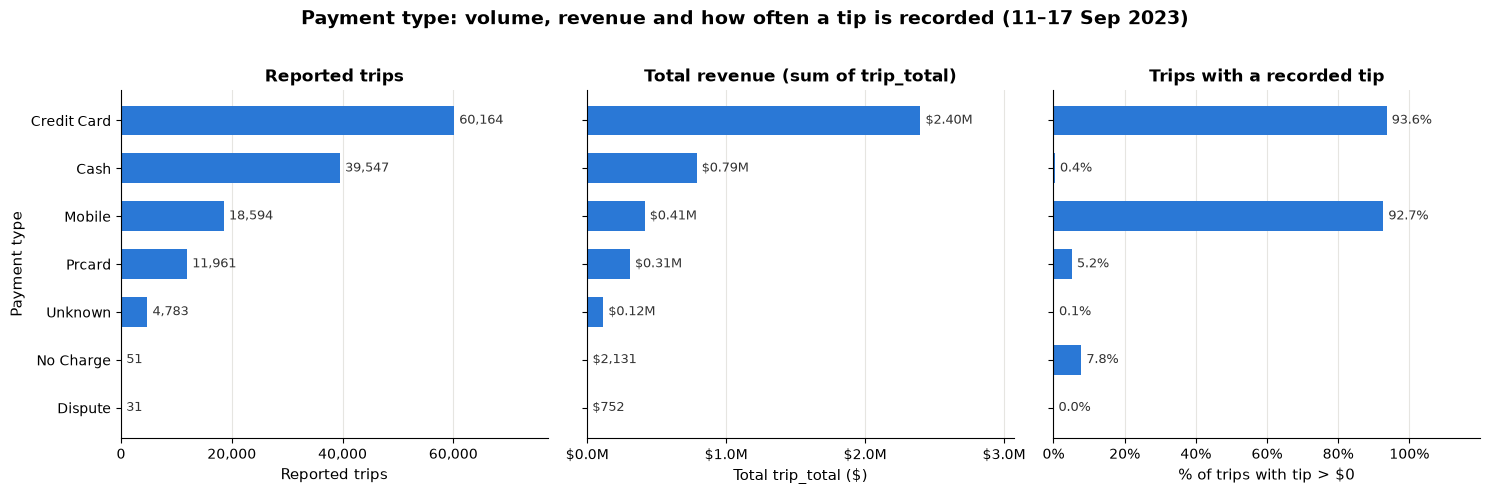

In [17]:
order = pay.index[::-1]   # largest at top
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
panels = [
    ("trips", "Reported trips", "Reported trips", lambda v: f"{v:,.0f}"),
    ("total_revenue", "Total revenue (sum of trip_total)", "Total trip_total ($)", lambda v: f"${v/1e6:,.2f}M" if v >= 1e5 else f"${v:,.0f}"),
    ("pct_trips_with_tip", "Trips with a recorded tip", "% of trips with tip > $0", lambda v: f"{v:,.1f}%"),
]
for ax, (col, title, xl, fmt) in zip(axes, panels):
    vals = pay.loc[order, col]
    ax.barh(vals.index, vals.values, color=BLUE, height=0.62)
    for y, v in enumerate(vals.values):
        ax.text(v + vals.max() * 0.015, y, fmt(v), va="center", fontsize=9, color="#333")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xl)
    ax.set_xlim(0, vals.max() * 1.28)
    ax.grid(axis="y", visible=False)
axes[0].set_ylabel("Payment type")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e6:,.1f}M"))
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].xaxis.set_major_locator(mtick.MultipleLocator(20000))
axes[1].xaxis.set_major_locator(mtick.MultipleLocator(1e6))
fig.suptitle("Payment type: volume, revenue and how often a tip is recorded (11–17 Sep 2023)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_payment_type.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q3).** Credit Card is the main payment type (44.5% of reported trips, 59.6% of revenue, average fare $28.78), followed by Cash (29.3% of trips, 19.6% of revenue, average fare $18.26) and Mobile (13.8% of trips, average fare $17.81, i.e. shorter or cheaper trips than Credit Card). Prcard (8.9%) and Unknown (3.5%) make up most of the rest; No Charge (51) and Dispute (31) are negligible. Tips are recorded on 93–94% of Credit Card and Mobile trips but on under 6% of every other type, so only those two are comparable: tips average about **22% of fare** (Credit Card 22.2%, Mobile 20.5%; median per trip 22.6% for the pair). The low figures for Cash (0.1%), Prcard (0.7%) and Unknown (0.02%) reflect tips that are not recorded, not riders who do not tip, and the overall 14.2% tip-to-fare ratio is understated for the same reason.
#
# *Possible follow-up:* find out what `Prcard` and `Unknown` represent, since together they are 12% of trips and carry almost no tip data.

# ## 5. Question 4 — Which companies carry the trips?

In [18]:
comp = clean.groupby("company").agg(
    trips=("trip_id","size"),
    total_revenue=("trip_total","sum"),
    distinct_taxis=("taxi_id","nunique"),
)
comp["pct_of_all_trips"] = comp["trips"] / len(clean) * 100
comp["pct_of_all_revenue"] = comp["total_revenue"] / clean["trip_total"].sum() * 100
comp["trips_per_taxi"] = comp["trips"] / comp["distinct_taxis"]
comp["avg_trip_total"] = comp["total_revenue"] / comp["trips"]
top_comp = comp.sort_values("trips", ascending=False).head(10)
print(top_comp.round(2).to_string())
print()
print("Top-10 share of all trips: {:.1%} | of revenue: {:.1%}".format(top_comp.trips.sum()/len(clean), top_comp.total_revenue.sum()/clean.trip_total.sum()))
print("Top-2 share of trips: {:.1%}".format(top_comp.trips.head(2).sum()/len(clean)))
print("Companies in total:", len(comp), "| other companies' trips:", int(len(clean) - top_comp.trips.sum()))
print("Distinct taxis in whole cleaned data:", clean.taxi_id.nunique(), "| sum of per-company distinct taxis:", int(comp.distinct_taxis.sum()))
multi = clean.groupby("taxi_id")["company"].nunique()
print("Taxis reported under more than one company:", int((multi > 1).sum()))

                              trips  total_revenue  distinct_taxis  pct_of_all_trips  pct_of_all_revenue  trips_per_taxi  avg_trip_total
company                                                                                                                                 
Flash Cab                     25887     683,880.16             401             19.16               16.99           64.56           26.42
Taxi Affiliation Services     25641     724,912.56             457             18.97               18.00           56.11           28.27
Taxicab Insurance Agency Llc  16142     523,553.88             356             11.95               13.00           45.34           32.43
Sun Taxi                      15060     482,016.67             299             11.14               11.97           50.37           32.01
City Service                  13640     420,218.71             265             10.09               10.44           51.47           30.81
Chicago Independents           7939     2

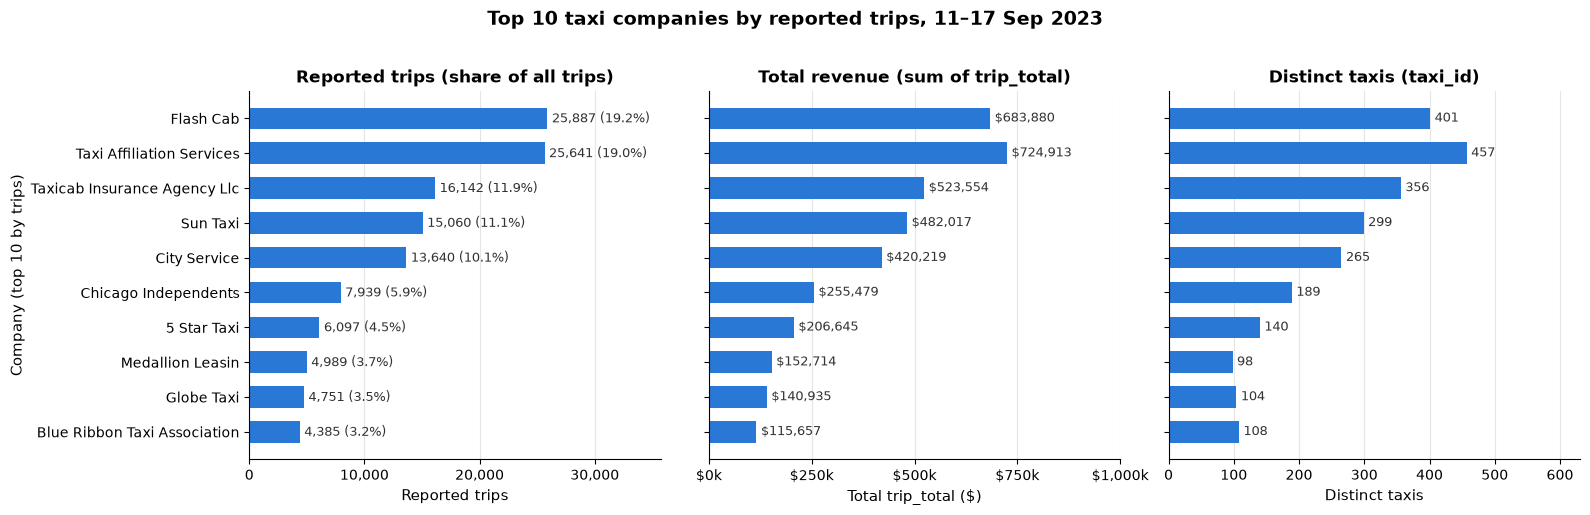

In [19]:
d = top_comp.iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
panels = [
    ("trips", "Reported trips (share of all trips)", "Reported trips", None),
    ("total_revenue", "Total revenue (sum of trip_total)", "Total trip_total ($)", None),
    ("distinct_taxis", "Distinct taxis (taxi_id)", "Distinct taxis", None),
]
for ax, (col, title, xl, _) in zip(axes, panels):
    vals = d[col]
    ax.barh(vals.index, vals.values, color=BLUE, height=0.62)
    for y, (name, v) in enumerate(vals.items()):
        if col == "trips":
            lab = f"{v:,.0f} ({d.loc[name, 'pct_of_all_trips']:.1f}%)"
        elif col == "total_revenue":
            lab = f"${v:,.0f}"
        else:
            lab = f"{v:,.0f}"
        ax.text(v + vals.max() * 0.015, y, lab, va="center", fontsize=9, color="#333")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xl)
    ax.set_xlim(0, vals.max() * 1.38)
    ax.grid(axis="y", visible=False)
axes[0].set_ylabel("Company (top 10 by trips)")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].xaxis.set_major_locator(mtick.MultipleLocator(10000))
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k"))
axes[1].xaxis.set_major_locator(mtick.MultipleLocator(250000))
axes[2].xaxis.set_major_locator(mtick.MultipleLocator(100))
fig.suptitle("Top 10 taxi companies by reported trips, 11–17 Sep 2023", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_top10_companies.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q4).** Two companies carry well over a third of reported trips: Flash Cab (25,887 trips, 19.2%) and Taxi Affiliation Services (25,641, 19.0%). The top five carry 71.3% and the top 10 carry 92.2% of trips (92.0% of revenue); the other 20 companies share the remaining 7.8%. Taxi Affiliation Services has the highest revenue ($724,913) despite slightly fewer trips than Flash Cab, because its average trip is larger ($28.27 vs $26.42), and it also has the largest fleet (457 distinct taxis vs 401). Flash Cab's taxis are the busiest of the top 10 (about 65 trips per taxi in the week, vs about 41–46 for Chicago Independents, 5 Star, Globe and Blue Ribbon). In total 2,656 distinct taxis appear; three taxi IDs are reported under two companies, so per-company counts add up to 2,659.
#
# *Possible follow-up:* compare trips per taxi and average fare across companies with more weeks of data to see whether the fleet-utilisation gaps persist.

# ## 6. Notes and limitations
#
# - All numbers describe **reported** trips for one week (11–17 September 2023) after the exclusions listed in Section 1 (637 of 135,768 rows, 0.47%); they do not represent total taxi market volume.
# - Hourly and daily patterns use start times rounded to 15 minutes. Tip rates are only meaningful for Credit Card and Mobile trips.
# - Pickup areas are shown by number; no outside data (names, weather, other weeks) was used.
# - A one-week window cannot show whether the Friday dip or the company shares are typical.